In [1]:
import os, re,time,random,warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pydicom

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)


ROOT = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
OUT  = Path("/kaggle/working")
IMG_DIR = ROOT / "train_series"
SEED = 42; random.seed(SEED); rng = np.random.default_rng(SEED)

UID = {"StudyInstanceUID": str, "SeriesInstanceUID": str}   # keep UIDs as strings, never floats
train  = pd.read_csv(ROOT / "train.csv", dtype=UID)
series = pd.read_csv(ROOT / "train_series.csv", dtype=UID)

LABELS = [c for c in train.columns if c not in ("StudyInstanceUID", "Report")]
train["is_gold"] = train[LABELS].notna().all(axis=1)
print(f"studies={len(train):,} series={len(series):,} gold={train.is_gold.sum()}")
print(LABELS)

studies=4,407 series=24,371 gold=58
['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


In [2]:
assert (series.Fluid_Sensitive == series.Fat_Suppression).all()
series["plane"] = series.Anatomical_Plane.str[:3].str.upper()
series["kind"]  = series.plane + np.where(series.Fat_Suppression == 1, "_FS", "_nonFS")

cov = (series.groupby(["StudyInstanceUID", "kind"]).size()
             .unstack(fill_value=0)
             .reindex(train.StudyInstanceUID, fill_value=0))

display(pd.DataFrame({
    "% studies having": (cov > 0).mean() * 100,
    "% with duplicates": (cov > 1).mean() * 100,
    "max per study": cov.max(),
}).round(1).sort_values("% studies having", ascending=False))

combo = (cov > 0).apply(lambda r: " + ".join(sorted(r.index[r])), axis=1)
display(combo.value_counts().head(10).to_frame("n_studies"))

fs_cols = [c for c in cov.columns if c.endswith("_FS")]
print(f"All 3 FS planes: {(cov[fs_cols] > 0).all(axis=1).mean()*100:.1f}%")
print(f"No SAG_FS: {(cov.get('SAG_FS', 0) == 0).sum()} studies")

,% studies having,% with duplicates,max per study
kind,,,
AXI_FS,100.0,6.8,3
SAG_nonFS,96.8,19.6,4
COR_FS,96.4,8.1,4
SAG_FS,94.2,11.6,3
COR_nonFS,77.3,12.9,3
AXI_nonFS,19.4,6.7,6


,n_studies
AXI_FS + COR_FS + COR_nonFS + SAG_FS + SAG_nonFS,2516
AXI_FS + COR_FS + SAG_FS + SAG_nonFS,745
AXI_FS + AXI_nonFS + COR_FS + COR_nonFS + SAG_FS + SAG_nonFS,566
AXI_FS + AXI_nonFS + COR_FS + SAG_nonFS,229
AXI_FS + COR_nonFS + SAG_FS + SAG_nonFS,157
AXI_FS + COR_FS + COR_nonFS + SAG_FS,120
AXI_FS + AXI_nonFS + COR_FS + SAG_FS + SAG_nonFS,23
AXI_FS + AXI_nonFS + COR_FS + COR_nonFS + SAG_FS,21
AXI_FS + AXI_nonFS + COR_FS + COR_nonFS + SAG_nonFS,16
AXI_FS + COR_FS + COR_nonFS + SAG_nonFS,8


All 3 FS planes: 90.6%
No SAG_FS: 257 studies


In [3]:
no_sag = cov[cov.get("SAG_FS", 0) == 0]
print("What the 257 studies without SAG_FS have instead:")
display((no_sag > 0).mean().mul(100).round(1).sort_values(ascending=False).to_frame("% of these"))
print("Gold studies among them:", train.set_index("StudyInstanceUID").loc[no_sag.index, "is_gold"].sum())

What the 257 studies without SAG_FS have instead:


,% of these
kind,
AXI_FS,100.0
COR_FS,100.0
SAG_nonFS,100.0
AXI_nonFS,95.3
COR_nonFS,9.3
SAG_FS,0.0


Gold studies among them: 2


In [4]:
def n_files(st, se):
    try: return len(os.listdir(IMG_DIR / st / se))
    except FileNotFoundError: return -1

cache = OUT / "slice_counts.csv"
if cache.exists():
    counts = pd.read_csv(cache, dtype=UID)
else:
    probe = series.sample(200, random_state=SEED)
    t0 = time.time(); [n_files(a, b) for a, b in zip(probe.StudyInstanceUID, probe.SeriesInstanceUID)]
    est = (time.time() - t0) / 200 * len(series) / 60
    print(f"Estimated full run: {est:.1f} min")
    target = series if est < 15 else series.sample(3000, random_state=SEED)
    counts = target[["StudyInstanceUID", "SeriesInstanceUID"]].copy()
    counts["n_slices"] = [n_files(a, b) for a, b in zip(counts.StudyInstanceUID, counts.SeriesInstanceUID)]
    counts.to_csv(cache, index=False)

series = series.merge(counts, on=["StudyInstanceUID", "SeriesInstanceUID"], how="left")
print("missing on disk:", (series.n_slices == -1).sum())
display(series.groupby("kind").n_slices.describe(percentiles=[.05, .5, .95]).round(1))


Estimated full run: 2.8 min
missing on disk: 0


,count,mean,std,min,5%,50%,95%,max
kind,,,,,,,,
AXI_FS,4719.0,39.5,32.0,12.0,19.0,32.0,144.0,192.0
AXI_nonFS,1179.0,41.0,32.0,14.0,24.0,32.0,80.7,254.0
COR_FS,4624.0,28.5,6.3,15.0,16.0,30.0,38.0,80.0
COR_nonFS,3985.0,28.0,6.1,11.0,16.0,30.0,37.0,48.0
SAG_FS,4667.0,35.5,41.5,15.0,19.0,29.0,47.0,320.0
SAG_nonFS,5197.0,33.7,21.2,11.0,20.0,30.0,60.4,200.0


In [5]:
s0 = series.iloc[0]
f0 = sorted((IMG_DIR / s0.StudyInstanceUID / s0.SeriesInstanceUID).iterdir())[0]
d0 = pydicom.dcmread(f0, stop_before_pixels=True)
print("Transfer syntax:", d0.file_meta.TransferSyntaxUID.name)
print(f"{len(d0)} tags:\n", ", ".join(e.keyword or str(e.tag) for e in d0))

Transfer syntax: Explicit VR Little Endian
63 tags:
 ImageType, SOPClassUID, SOPInstanceUID, Modality, Manufacturer, SeriesDescription, ManufacturerModelName, PatientID, PatientSex, ContrastBolusAgent, BodyPartExamined, ScanningSequence, SequenceVariant, ScanOptions, MRAcquisitionType, SliceThickness, RepetitionTime, EchoTime, NumberOfAverages, ImagingFrequency, EchoNumbers, MagneticFieldStrength, SpacingBetweenSlices, NumberOfPhaseEncodingSteps, EchoTrainLength, PercentSampling, PercentPhaseFieldOfView, PixelBandwidth, SoftwareVersions, ReceiveCoilName, AcquisitionMatrix, InPlanePhaseEncodingDirection, FlipAngle, PatientPosition, DiffusionBValue, DiffusionGradientOrientation, StudyInstanceUID, SeriesInstanceUID, SeriesNumber, AcquisitionNumber, InstanceNumber, ImagePositionPatient, ImageOrientationPatient, FrameOfReferenceUID, Laterality, NumberOfTemporalPositions, SliceLocation, SamplesPerPixel, PhotometricInterpretation, PlanarConfiguration, NumberOfFrames, Rows, Columns, PixelSpaci

In [6]:
def g(ds, key, default=None):
    v = getattr(ds, key, None)
    if v is None or v == "": return default
    if isinstance(v, pydicom.multival.MultiValue):
        try: return [float(x) for x in v]
        except (TypeError, ValueError): return "\\".join(map(str, v))
    if isinstance(v, (pydicom.valuerep.DSfloat, pydicom.valuerep.IS)): return float(v)
    if isinstance(v, pydicom.valuerep.PersonName): return str(v)
    return v

In [7]:
STUDY_TAGS = ["PatientID", "PatientSex", "Manufacturer", "ManufacturerModelName", "MagneticFieldStrength",
              "SoftwareVersions", "ReceiveCoilName", "BodyPartExamined", "Laterality", "ContrastBolusAgent"]
cache = OUT / "study_headers.csv"
if cache.exists():
    sh = pd.read_csv(cache, dtype={**UID, "PatientID": str})
else:
    first = series.drop_duplicates("StudyInstanceUID")
    recs, t0 = [], time.time()
    for i, r in enumerate(first.itertuples()):
        f = next(os.scandir(IMG_DIR / r.StudyInstanceUID / r.SeriesInstanceUID)).path
        ds = pydicom.dcmread(f, stop_before_pixels=True)
        recs.append({"StudyInstanceUID": r.StudyInstanceUID, **{t: g(ds, t) for t in STUDY_TAGS}})
        if i % 500 == 0: print(i, f"{time.time()-t0:.0f}s")
    sh = pd.DataFrame(recs); sh.to_csv(cache, index=False)
print("done:", len(sh))

0 0s
500 6s
1000 11s
1500 16s
2000 20s
2500 25s
3000 29s
3500 34s
4000 39s
done: 4407


In [8]:
vc = sh.PatientID.value_counts()
print(f"unique PatientIDs: {sh.PatientID.nunique()} for {len(sh)} studies (null: {sh.PatientID.isna().sum()})")
print(f"patients with >1 study: {(vc > 1).sum()}  | studies involved: {vc[vc > 1].sum()}")
print("example PatientIDs:", sh.PatientID.dropna().head(3).tolist())

for c in ["PatientSex", "Manufacturer", "MagneticFieldStrength", "BodyPartExamined", "Laterality", "ContrastBolusAgent"]:
    print(f"\n{c}:", sh[c].value_counts(dropna=False).head(8).to_dict())

sh["scanner"] = (sh.Manufacturer.fillna("?") + " | " + sh.ManufacturerModelName.fillna("?")
                 + " | " + sh.MagneticFieldStrength.astype(str))
print(f"\n{sh.scanner.nunique()} distinct scanner fingerprints. Top 15:")
display(sh.scanner.value_counts().head(15).to_frame("studies"))

sh["is_gold"] = sh.StudyInstanceUID.isin(train.loc[train.is_gold, "StudyInstanceUID"])
print("Gold studies by vendor:")
display(pd.crosstab(sh.Manufacturer.fillna("?"), sh.is_gold))

unique PatientIDs: 4407 for 4407 studies (null: 0)
patients with >1 study: 0  | studies involved: 0
example PatientIDs: ['b9d20b75-edf', 'ee084a79-b22', 'f7648f12-847']

PatientSex: {'M': 2076, 'F': 1894, None: 238, 'O': 199}

Manufacturer: {'Siemens Healthineers': 1053, 'GE MEDICAL SYSTEMS': 868, 'SIEMENS': 804, 'Philips Medical Systems': 718, 'Philips': 492, 'TOSHIBA': 181, 'Siemens': 94, 'Philips Healthcare': 91}

MagneticFieldStrength: {1.5: 2543, 3.0: 1601, nan: 238, 1.16: 24, 1.0: 1}

BodyPartExamined: {'KNEE': 3476, 'EXTREMITY': 443, None: 415, 'ANKLE': 16, 'WRIST': 14, 'HEAD': 10, 'BRAIN': 6, 'LIVER': 4}

Laterality: {None: 2221, 'R': 1087, 'L': 1079, 'RIGHT': 12, 'LEFT': 7, 'B': 1}

ContrastBolusAgent: {None: 4405, 'right': 1, 'LEFT': 1}

58 distinct scanner fingerprints. Top 15:


,studies
scanner,
Philips Medical Systems | Ingenia | 3.0,450
SIEMENS | Aera | 1.5,400
Siemens Healthineers | MAGNETOM Vida | 3.0,353
Siemens Healthineers | MAGNETOM Avanto fit | 1.5,262
SIEMENS | SonataVision | 1.5,214
GE MEDICAL SYSTEMS | SIGNA Explorer | 1.5,213
GE MEDICAL SYSTEMS | SIGNA Artist | 1.5,208
Philips | Achieva dStream | 3.0,141
TOSHIBA | Vantage | nan,129


Gold studies by vendor:


is_gold,False,True
Manufacturer,,
CANON_MEC,44,1
FUJIFILM Healthcare Corporation,16,0
GE MEDICAL SYSTEMS,852,16
GEHC,37,0
Hitachi Medical Corporation,8,0
Philips,485,7
Philips Healthcare,89,2
Philips Medical Systems,709,9
SIEMENS,793,11


In [9]:
def audit_series(st, se):
    files = sorted((IMG_DIR / st / se).iterdir())
    rows = []
    for f in files:
        ds = pydicom.dcmread(f, stop_before_pixels=True)
        rows.append(dict(inst=g(ds, "InstanceNumber"), pos=g(ds, "ImagePositionPatient"), ori=g(ds, "ImageOrientationPatient"),
                         rows=g(ds, "Rows"), cols=g(ds, "Columns"), px=g(ds, "PixelSpacing"), thick=g(ds, "SliceThickness"),
                         frames=g(ds, "NumberOfFrames", 1), acq=g(ds, "MRAcquisitionType"), te=g(ds, "EchoTime"),
                         tr=g(ds, "RepetitionTime"), seq=g(ds, "ScanningSequence"), desc=g(ds, "SeriesDescription"),
                         lat=g(ds, "Laterality"), contrast=g(ds, "ContrastBolusAgent")))
    df = pd.DataFrame(rows)
    out = dict(StudyInstanceUID=st, SeriesInstanceUID=se, n=len(df))
    for k in ["rows", "cols", "thick", "frames", "acq", "te", "tr", "seq", "desc", "lat", "contrast"]:
        v = df[k].dropna(); out[k] = v.mode().iloc[0] if len(v) else None
    out["n_matrix_sizes"] = df[["rows", "cols"]].drop_duplicates().shape[0]
    out["px"] = df.px.dropna().iloc[0][0] if df.px.notna().any() else None
    if df.ori.notna().all() and df.pos.notna().all():
        o = np.array(df.ori.iloc[0]); nrm = np.cross(o[:3], o[3:])
        out["plane_from_ori"] = {0: "SAG", 1: "COR", 2: "AXI"}[int(np.argmax(np.abs(nrm)))]
        out["oblique_deg"] = float(np.degrees(np.arccos(np.abs(nrm).max() / np.linalg.norm(nrm))))
        proj = np.array([np.dot(p, nrm) for p in df.pos]); sp = np.argsort(proj); io = np.argsort(df.inst.values)
        out["inst_matches_spatial"] = bool(np.array_equal(io, sp) or np.array_equal(io, sp[::-1]))
        gaps = np.diff(np.sort(proj))
        out["spacing_mm"] = float(np.median(gaps))
        out["dup_positions"] = int((gaps < 1e-3).sum())
        out["irregular"] = bool(gaps.max() > 1.5 * np.median(gaps)) if np.median(gaps) > 0 else True
    return out

cache = OUT / "series_header_audit.csv"
if cache.exists():
    hdr = pd.read_csv(cache, dtype=UID)
else:
    s_ok = series[series.n_slices > 0]
    samp = pd.concat([s_ok.groupby("kind", group_keys=False).apply(lambda d: d.sample(min(30, len(d)), random_state=SEED)),
                      s_ok[s_ok.n_slices > 100].sample(30, random_state=SEED)]).drop_duplicates("SeriesInstanceUID")
    recs, t0 = [], time.time()
    for i, r in enumerate(samp.itertuples()):
        try: recs.append(audit_series(r.StudyInstanceUID, r.SeriesInstanceUID))
        except Exception as e: recs.append(dict(StudyInstanceUID=r.StudyInstanceUID, SeriesInstanceUID=r.SeriesInstanceUID, error=repr(e)))
        if i % 25 == 0: print(f"{i}/{len(samp)} {time.time()-t0:.0f}s")
    hdr = pd.DataFrame(recs); hdr.to_csv(cache, index=False)
hdr = hdr.merge(series[["SeriesInstanceUID", "plane", "kind"]], on="SeriesInstanceUID", how="left")
print("audited:", len(hdr), "| errors:", hdr["error"].notna().sum() if "error" in hdr else 0)

0/210 0s
25/210 12s
50/210 23s
75/210 30s
100/210 38s
125/210 46s
150/210 52s
175/210 60s
200/210 96s
audited: 210 | errors: 0


== CSV plane vs plane from orientation ==


plane_from_ori,AXI,COR,SAG
plane,,,
AXI,78,0,0
COR,0,60,0
SAG,0,0,72


== InstanceNumber order == spatial order? == {True: 210}
dup positions: 0 | irregular spacing: 0 | >1 matrix size: 0 | multi-frame files: 0

== 2D/3D vs slice count ==


acq,2D,3D,?
size_bucket,,,
<=60,162,1,9
61-100,0,3,0
>100,0,35,0


,spacing_mm,thick,px,rows
acq,,,,
2D,3.5,3.0,0.31,512.0
3D,0.6,0.8,0.28,640.0



== Top SeriesDescriptions per kind ==
AXI_FS     {'t2_de3d_we_tra_Patella_fit_T': 14, 'pd_tse_fs_tra_320': 3, 'AX PD FS MPR R': 3, 'DummySeriesDesc!': 3, 'pd_tse_fs_tra_p2_320': 2}
AXI_nonFS  {'pd_tse_tra_d': 8, 't1_vibe_we_tra_cartilage': 5, 'RT.Tra_T1W_TSE': 2, 'LT.AX_T1W_TSE': 2, '3D_WATSc': 2}
COR_FS     {'DummySeriesDesc!': 5, 'pd_tse_fs_cor_320': 4, 'PDW_TSE_SPAIR_Cor': 2, 'pd_tse_fs_cor_384': 2, 'CO T2W FS': 2}
COR_nonFS  {'t2_tse_bond_416': 4, 'COR T1': 3, 't1_tse_cor_448_p2_s2': 2, 't1_tse_cor_s2p2_448_DRB': 2, 'Cor T1 FSE': 2}
SAG_FS     {'Sag PD FSE FS': 4, 'DummySeriesDesc!': 3, 'SAG 3D_VIEW_PD_SPAIR_HR R': 3, 'pd_tse_fs_sag_np': 2, 'pd_tse_fs_sag_384': 2}
SAG_nonFS  {'DummySeriesDesc!': 13, 't1_tse_sag_384': 4, 'SAG PD': 3, 'Sag T2 FSE': 2, 't1_se_sag_320': 2}


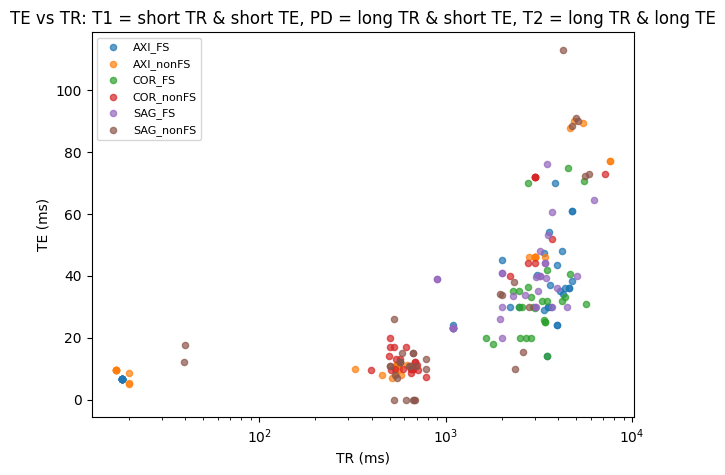

In [10]:
print("== CSV plane vs plane from orientation =="); display(pd.crosstab(hdr.plane, hdr.plane_from_ori))
print("== InstanceNumber order == spatial order? ==", hdr.inst_matches_spatial.value_counts(dropna=False).to_dict())
print("dup positions:", (hdr.dup_positions > 0).sum(), "| irregular spacing:", hdr.irregular.sum(),
      "| >1 matrix size:", (hdr.n_matrix_sizes > 1).sum(), "| multi-frame files:", (hdr.frames > 1).sum())

hdr["size_bucket"] = pd.cut(hdr.n, [0, 60, 100, 1000], labels=["<=60", "61-100", ">100"])
print("\n== 2D/3D vs slice count =="); display(pd.crosstab(hdr.size_bucket, hdr.acq.fillna("?")))
display(hdr.groupby("acq")[["spacing_mm", "thick", "px", "rows"]].median().round(2))

print("\n== Top SeriesDescriptions per kind ==")
for k, d in hdr.groupby("kind"): print(f"{k:10s}", d.desc.value_counts().head(5).to_dict())

fig, ax = plt.subplots(figsize=(7, 5))
for k, d in hdr.groupby("kind"): ax.scatter(d.tr, d.te, label=k, alpha=.7, s=20)
ax.set_xscale("log"); ax.set_xlabel("TR (ms)"); ax.set_ylabel("TE (ms)"); ax.legend(fontsize=8)
ax.set_title("TE vs TR: T1 = short TR & short TE, PD = long TR & short TE, T2 = long TR & long TE"); plt.show()

In [11]:
no_sag_ids = no_sag.index
sub = series[series.StudyInstanceUID.isin(no_sag_ids) & (series.kind == "SAG_nonFS")]
print("SAG_nonFS series per study (among the 257):", sub.groupby("StudyInstanceUID").size().value_counts().to_dict())
print("\nScanners of these 257 studies:"); display(sh[sh.StudyInstanceUID.isin(no_sag_ids)].scanner.value_counts().head(5))

recs = []
for r in sub.itertuples():
    ds = pydicom.dcmread(next(os.scandir(IMG_DIR / r.StudyInstanceUID / r.SeriesInstanceUID)).path, stop_before_pixels=True)
    recs.append(dict(StudyInstanceUID=r.StudyInstanceUID, SeriesInstanceUID=r.SeriesInstanceUID, n=r.n_slices,
                     desc=g(ds, "SeriesDescription"), te=g(ds, "EchoTime"), tr=g(ds, "RepetitionTime"),
                     acq=g(ds, "MRAcquisitionType")))
ns = pd.DataFrame(recs)
print("\nTheir SeriesDescriptions:"); display(ns.desc.value_counts().head(10))
ns["contrast_guess"] = np.where(ns.tr < 1000, "T1-like", np.where(ns.te < 60, "PD-like", "T2-like"))
display(ns.contrast_guess.value_counts())

SAG_nonFS series per study (among the 257): {2: 248, 1: 6, 3: 3}

Scanners of these 257 studies:


scanner
Siemens Healthineers | MAGNETOM Avanto fit | 1.5           245
SIEMENS | SonataVision | 1.5                                 6
Philips Medical Systems | Ingenia | 3.0                      2
FUJIFILM Healthcare Corporation | OASIS_Velocity | 1.16      1
SIEMENS | Verio_DOT | 3.0                                    1
Name: count, dtype: int64


Their SeriesDescriptions:


desc
pd_tse_sag_d             244
t2_tse_sag_d             243
t2_me2d_sag                6
DummySeriesDesc!           4
SAG PD                     2
pd_tse_fs_sag_np           2
pd_tse_sag_Metall_wip      1
Sag PD                     1
SAG T1 FS                  1
t1_tse_sag_d               1
Name: count, dtype: int64

contrast_guess
PD-like    256
T2-like    245
T1-like     10
Name: count, dtype: int64

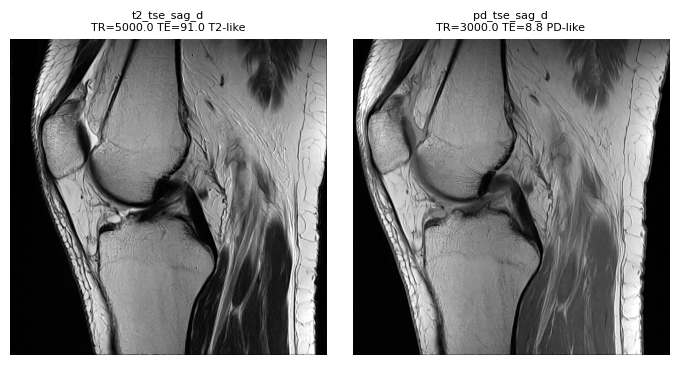

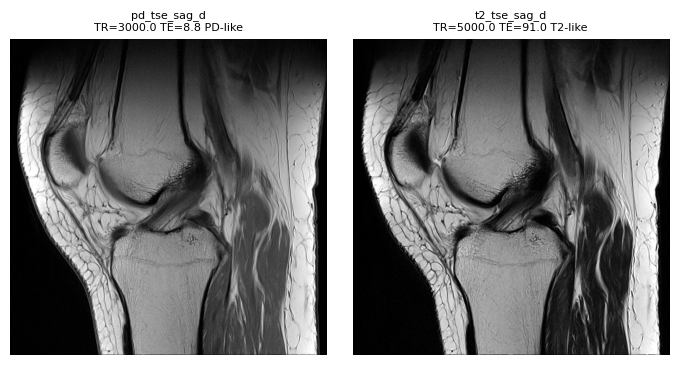

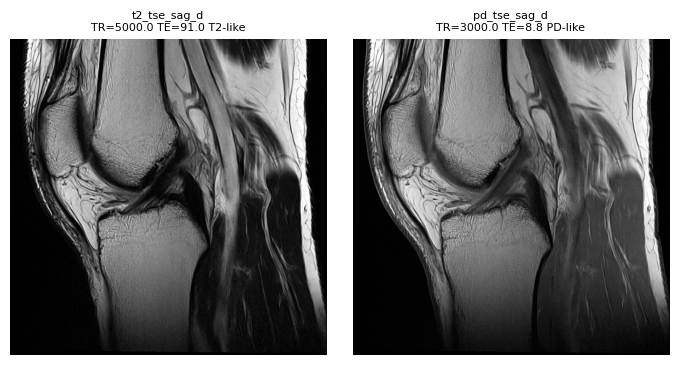

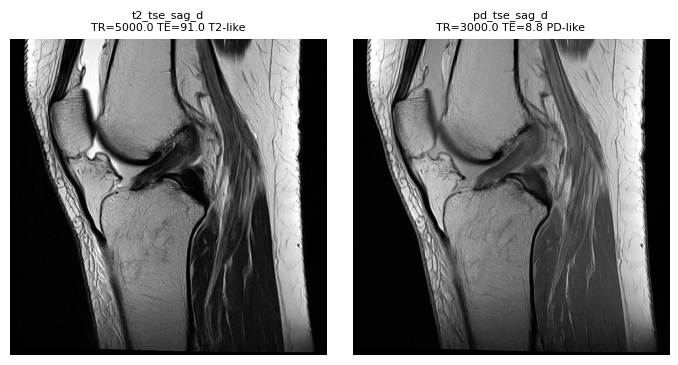

In [12]:
def load_mid(st, se):
    files = sorted((IMG_DIR / st / se).iterdir())
    inst = [float(pydicom.dcmread(f, stop_before_pixels=True).InstanceNumber) for f in files]
    a = pydicom.dcmread(files[np.argsort(inst)[len(files) // 2]]).pixel_array.astype(np.float32)
    lo, hi = np.percentile(a, [1, 99.5]); return np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)

studies = ns.StudyInstanceUID.drop_duplicates().sample(4, random_state=SEED)
for st in studies:
    d = ns[ns.StudyInstanceUID == st]
    fig, axes = plt.subplots(1, len(d), figsize=(3.5 * len(d), 3.6))
    for ax, r in zip(np.atleast_1d(axes), d.itertuples()):
        ax.imshow(load_mid(st, r.SeriesInstanceUID), cmap="gray"); ax.axis("off")
        ax.set_title(f"{r.desc}\nTR={r.tr} TE={r.te} {r.contrast_guess}", fontsize=8)
    plt.tight_layout(); plt.show()

{'Siemens': 1951, 'Philips': 1301, 'GE': 905, 'Canon/Toshiba': 226, 'Fujifilm/Hitachi': 24}
decode errors: 0 | dtypes: {'uint16': 147, 'int16': 63}


,max,p99,frac_zero
vendor,,,
Canon/Toshiba,8075.5,4214.79,0.04
GE,1704.0,1046.00,0.05
Philips,1636.0,1136.00,0.16
Siemens,987.0,523.00,0.02


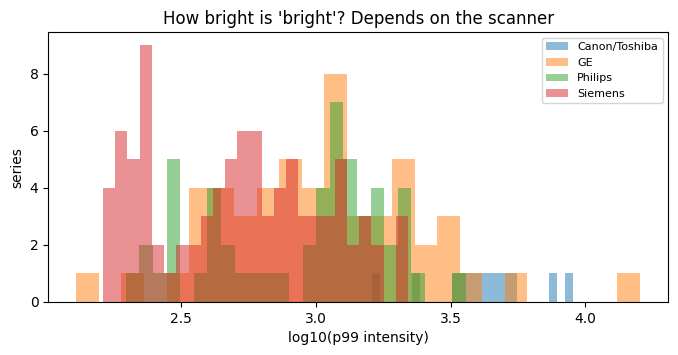

In [13]:
VENDOR_MAP = {"siemens": "Siemens", "ge": "GE", "philips": "Philips", "toshiba": "Canon/Toshiba",
              "canon": "Canon/Toshiba", "hitachi": "Fujifilm/Hitachi", "fujifilm": "Fujifilm/Hitachi"}
def norm_vendor(m):
    if not isinstance(m, str): return "Unknown"
    m = m.lower()
    return next((v for k, v in VENDOR_MAP.items() if m.startswith(k)), "Other")
sh["vendor"] = sh.Manufacturer.map(norm_vendor)
print(sh.vendor.value_counts().to_dict())

def load_raw_mid(st, se):
    files = sorted((IMG_DIR / st / se).iterdir())
    inst = [float(pydicom.dcmread(f, stop_before_pixels=True).InstanceNumber) for f in files]
    ds = pydicom.dcmread(files[np.argsort(inst)[len(files) // 2]])
    a = ds.pixel_array
    return a.astype(np.float32) * float(getattr(ds, "RescaleSlope", 1) or 1) + float(getattr(ds, "RescaleIntercept", 0) or 0), str(a.dtype)

pix = []
for r in hdr.merge(sh[["StudyInstanceUID", "vendor"]], on="StudyInstanceUID").itertuples():
    try:
        a, dt = load_raw_mid(r.StudyInstanceUID, r.SeriesInstanceUID)
        p = np.percentile(a, [1, 50, 99])
        pix.append(dict(kind=r.kind, vendor=r.vendor, dtype=dt, min=a.min(), max=a.max(),
                        p1=p[0], p50=p[1], p99=p[2], frac_zero=(a == 0).mean()))
    except Exception as e:
        pix.append(dict(kind=r.kind, error=repr(e)))
pix = pd.DataFrame(pix)
print("decode errors:", pix["error"].notna().sum() if "error" in pix else 0, "| dtypes:", pix.dtype.value_counts().to_dict())
display(pix.groupby("vendor")[["max", "p99", "frac_zero"]].median().round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
for v, d in pix.groupby("vendor"): ax.hist(np.log10(d.p99.clip(lower=1)), bins=25, alpha=.5, label=v)
ax.set_xlabel("log10(p99 intensity)"); ax.set_ylabel("series"); ax.legend(fontsize=8)
ax.set_title("How bright is 'bright'? Depends on the scanner"); plt.show()

In [14]:
!pip install -q langdetect
from langdetect import detect, DetectorFactory; DetectorFactory.seed = 0
def lang_of(t):
    try: return detect(t[:2000])
    except Exception: return "unk"

train["Report"]  = train.Report.fillna("")
train["lang"]    = train.Report.map(lang_of)
train["n_chars"] = train.Report.str.len()
lang_tab = train.groupby("lang").agg(n=("lang", "size"), gold=("is_gold", "sum"), median_chars=("n_chars", "median"))
lang_tab = lang_tab.sort_values("n", ascending=False); lang_tab["%"] = (lang_tab.n / len(train) * 100).round(1)
print("empty reports:", (train.n_chars == 0).sum()); display(lang_tab)

# Site proxy = scanner fingerprint + language
m = train[["StudyInstanceUID", "lang"]].merge(sh[["StudyInstanceUID", "scanner", "vendor"]], on="StudyInstanceUID")
print("Language x vendor (studies):"); display(pd.crosstab(m.lang, m.vendor).loc[lang_tab.index[:10]])

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
empty reports: 0


,n,gold,median_chars,%
lang,,,,
en,1736,28,1270.0,39.4
es,682,10,752.5,15.5
tr,546,6,692.5,12.4
hr,406,4,1172.5,9.2
el,321,3,858.0,7.3
de,262,2,807.0,5.9
bg,220,3,999.0,5.0
nl,153,2,918.0,3.5
fr,81,0,1560.0,1.8


Language x vendor (studies):


vendor,Canon/Toshiba,Fujifilm/Hitachi,GE,Philips,Siemens
lang,,,,,
en,226,24,479,590,417
es,0,0,137,335,210
tr,0,0,289,36,221
hr,0,0,0,120,286
el,0,0,0,0,321
de,0,0,0,0,262
bg,0,0,0,220,0
nl,0,0,0,0,153
fr,0,0,0,0,81


In [15]:
for lang in lang_tab.index[:6]:
    for t in train.loc[train.lang == lang, "Report"].sample(2, random_state=SEED):
        print(f"--- [{lang}] ---\n{t[:700]}{' ...' if len(t) > 700 else ''}\n")

--- [en] ---
Exam Type: MRI KNEE LEFT WO CONTRAST
Exam Date and Time: [DATE] [TIME]
Indication: One month of atraumatic knee pain
Comparison: No relevant prior studies available for comparison.

TECHNIQUE:
MRI of the left knee was performed on a 1.5 Tesla system with a dedicated knee coil in three planes (axial, sagittal, and coronal), using a standard non-contrast protocol.

FINDINGS:
OSSEOUS STRUCTURES:
Alignment is anatomic. No acute fracture or bone bruise. Background marrow signal is normal without infiltrative marrow process. No aggressive osseous lesions.

JOINT SPACE:
Moderate joint effusion. No intra-articular bodies. No Baker's cyst.

MEDIAL COMPARTMENT:
Medial meniscus: Full-thickness radial t ...

--- [en] ---
  The study reveals normal knee joint alignment.   NO fracture or bone contusion is seen. 
   Thickened mild hyperintense MCL is noted.   Myxoid degenerative change of the medial meniscus 
 without tear is observed.    
  Thickened distal semimembranosus tendon down t

In [16]:
hc = Counter()
for t in train.Report:
    for line in re.split(r"\n|\\n", t):
        s = line.strip()
        if 2 < len(s) < 40 and (s.endswith(":") or (s.isupper() and len(s.split()) <= 4)):
            hc[s.rstrip(":").strip().upper()] += 1
display(pd.Series(dict(hc.most_common(30))).to_frame("count"))

,count
IMPRESSION,632
FINDINGS,537
LATERAL COMPARTMENT,360
MEDIAL COMPARTMENT,359
TECHNIQUE,356
EXTENSOR MECHANISM,352
HALLAZGOS,348
IMPRESIÓN,347
PATELLOFEMORAL COMPARTMENT,347
CRUCIATE LIGAMENTS,347


In [17]:
avanto = sh[sh.scanner.str.contains("Avanto fit", na=False)].StudyInstanceUID
print(train[train.StudyInstanceUID.isin(avanto)].lang.value_counts().to_dict())

{'de': 262}


In [18]:
KW = {
    "Effusion": r"effusion|derrame|efüzyon|izljev|υγρ|ύδραρθρ|erguss|излив|effusie|hydrops|épanchement",
    "Fracture": r"fractur|fraktur|kırık|prijelom|κάταγμ|фрактур|счупван|fractuur",
    "Baker's":  r"baker|бейкър|μπέικερ|bejker",
}
NEG = (r"\b(no|not|without|negative|sin|yok|yoktur|nema|bez|ne|δεν|χωρίς|ουδέν|kein\w*|ohne|nicht|"
       r"няма|без|не|geen|zonder|niet|pas|sans|aucun\w*|absence)\b|izlenme|saptanma|görülme|rastlanma")

def sents(t): return [s for s in re.split(r"[.;!?]\s+|\n", t.lower()) if s.strip()]
def classify(t, pat):
    hits = [s for s in sents(t) if re.search(pat, s)]
    if not hits: return "absent"
    return "negated" if all(re.search(NEG, s) for s in hits) else "positive"

gold = train[train.is_gold].copy()
rows = []
for lab, pat in KW.items():
    y = gold[lab].astype(int); st = gold.Report.map(lambda t: classify(t, pat))
    naive, aware = st != "absent", st == "positive"
    pr = lambda p: (round((p & (y == 1)).sum() / max(p.sum(), 1), 2), round((p & (y == 1)).sum() / max(y.sum(), 1), 2))
    rows.append(dict(label=lab, positives=y.sum(), mentioned=naive.sum(), negated=(st == "negated").sum(),
                     precision_naive=pr(naive)[0], recall_naive=pr(naive)[1],
                     precision_negaware=pr(aware)[0], recall_negaware=pr(aware)[1]))
display(pd.DataFrame(rows))

# The most instructive part: where does even the negation-aware version get it WRONG?
for lab, pat in KW.items():
    print(f"\n===== {lab}: errors of the negation-aware probe =====")
    n = 0
    for _, r in gold.iterrows():
        pred = classify(r.Report, pat) == "positive"
        if pred != bool(r[lab]) and n < 4:
            n += 1
            hit = [s.strip()[:200] for s in sents(r.Report) if re.search(pat, s)]
            print(f"[{r.lang}] gold={int(r[lab])} pred={int(pred)} | {hit if hit else '(keyword never mentioned)'}")

,label,positives,mentioned,negated,precision_naive,recall_naive,precision_negaware,recall_negaware
0,Effusion,35,50,7,0.60,0.86,0.65,0.80
1,Fracture,18,20,7,0.50,0.56,0.69,0.50
2,Baker's,12,17,5,0.41,0.58,0.58,0.58



===== Effusion: errors of the negation-aware probe =====
[en] gold=0 pred=1 | ['moderate joint effusion, distended suprapatellar bursa with thickend synovial tissue are observed']
[en] gold=0 pred=1 | ['small joint effusion']
[en] gold=0 pred=1 | ['* some joint effusion of right knee with mild hypertrophy of the synovium, indicative of synovitis']
[bg] gold=0 pred=1 | ['наличие на минимален ставен излив', 'минимален ставен излив']

===== Fracture: errors of the negation-aware probe =====
[en] gold=0 pred=1 | ['no fracture is seen', 'osteochondral fracture at lateral patellar facet, about 8x12mm']
[en] gold=1 pred=0 | ['subchondral insufficiency fracture at the medial margin of the medial tibial plateau without articular surface collapse', 'subchondral insufficiency fracture at the medial margin of the medial tibial plateau without articular surface collapse']
[es] gold=1 pred=0 | (keyword never mentioned)
[tr] gold=1 pred=0 | (keyword never mentioned)

===== Baker's: errors of the neg

Findings per gold study: {'count': 58.0, 'mean': 4.1, 'std': 2.2, 'min': 1.0, '25%': 2.2, '50%': 4.0, '75%': 6.0, 'max': 9.0}


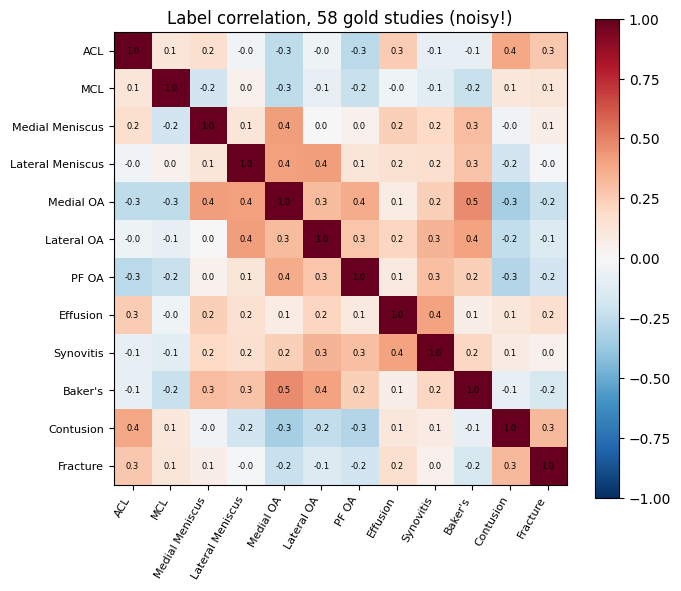

In [19]:
gl = train.loc[train.is_gold, LABELS].astype(int)
print("Findings per gold study:", gl.sum(axis=1).describe().round(1).to_dict())
corr = gl.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(12)); ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(12)); ax.set_yticklabels(LABELS, fontsize=8)
for i in range(12):
    for j in range(12): ax.text(j, i, f"{corr.iat[i, j]:.1f}", ha="center", va="center", fontsize=6)
plt.colorbar(im); ax.set_title("Label correlation, 58 gold studies (noisy!)"); plt.tight_layout(); plt.show()

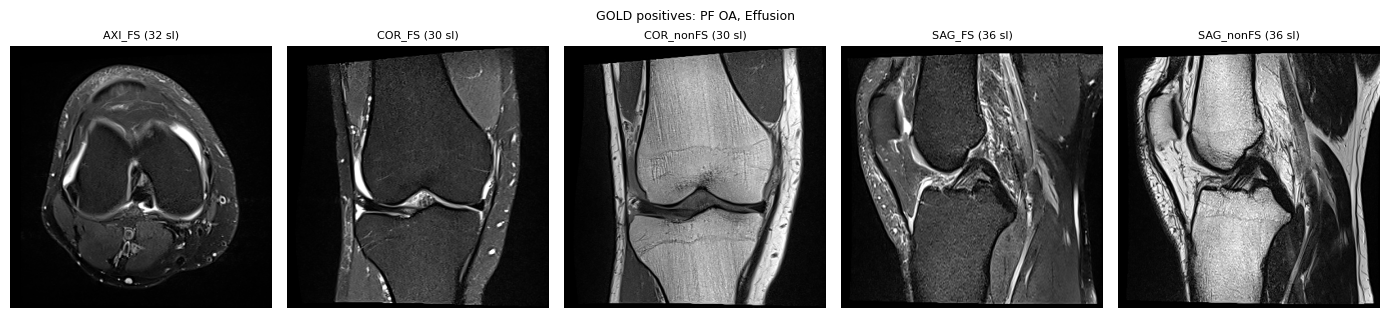

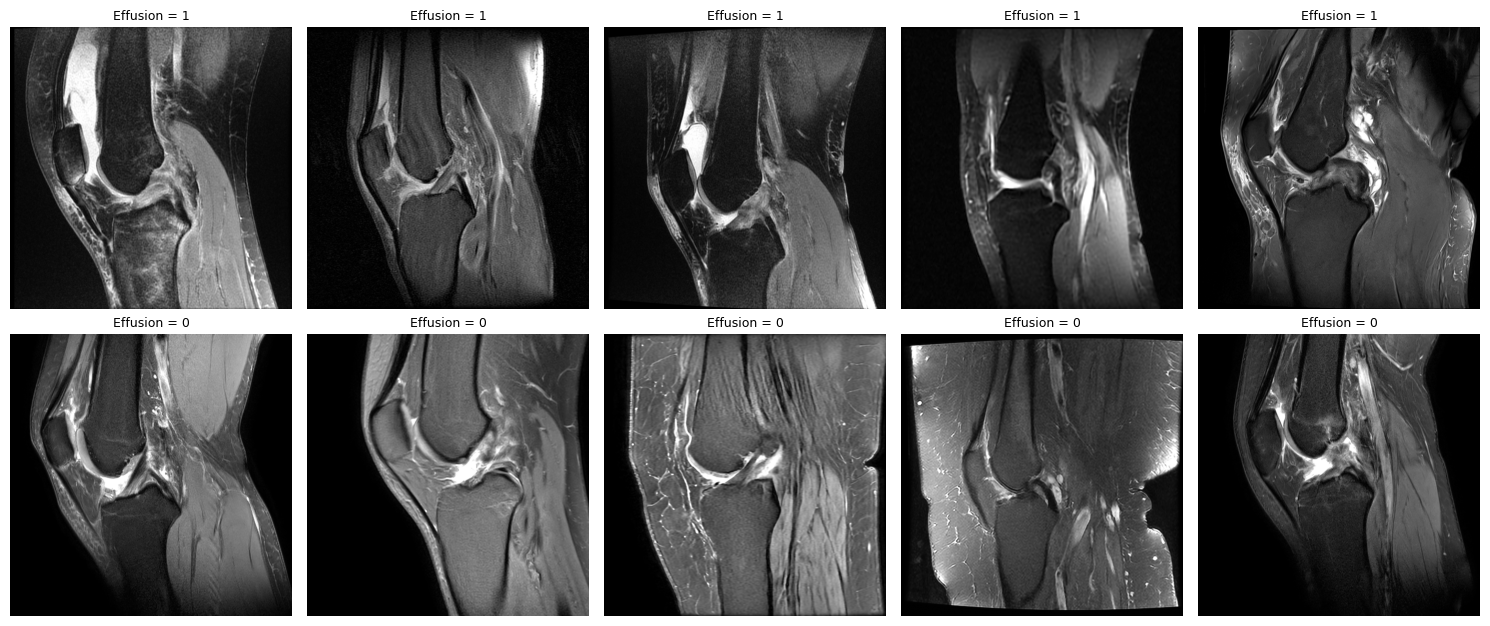

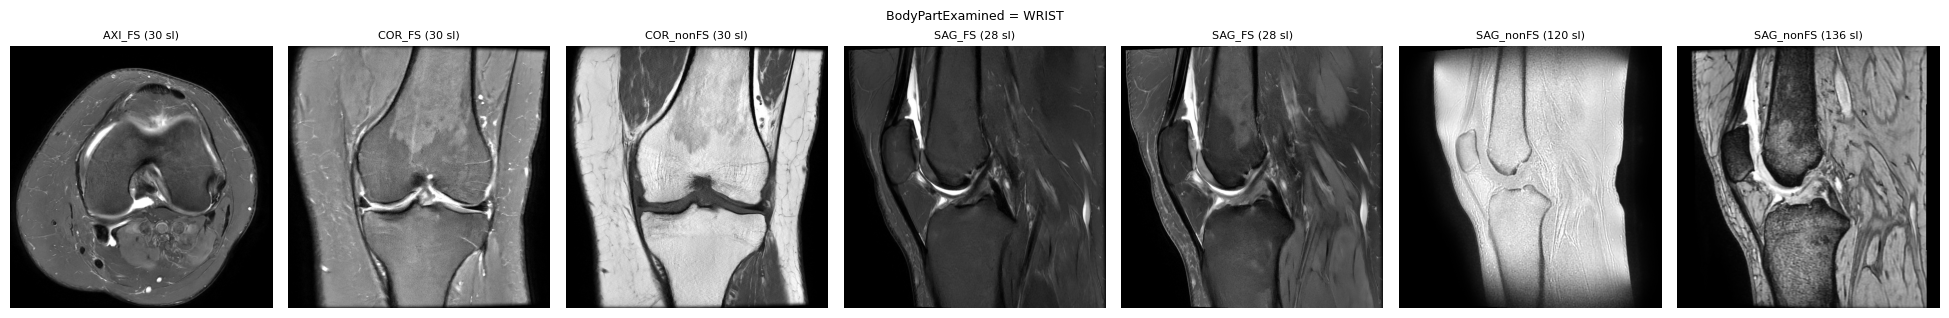

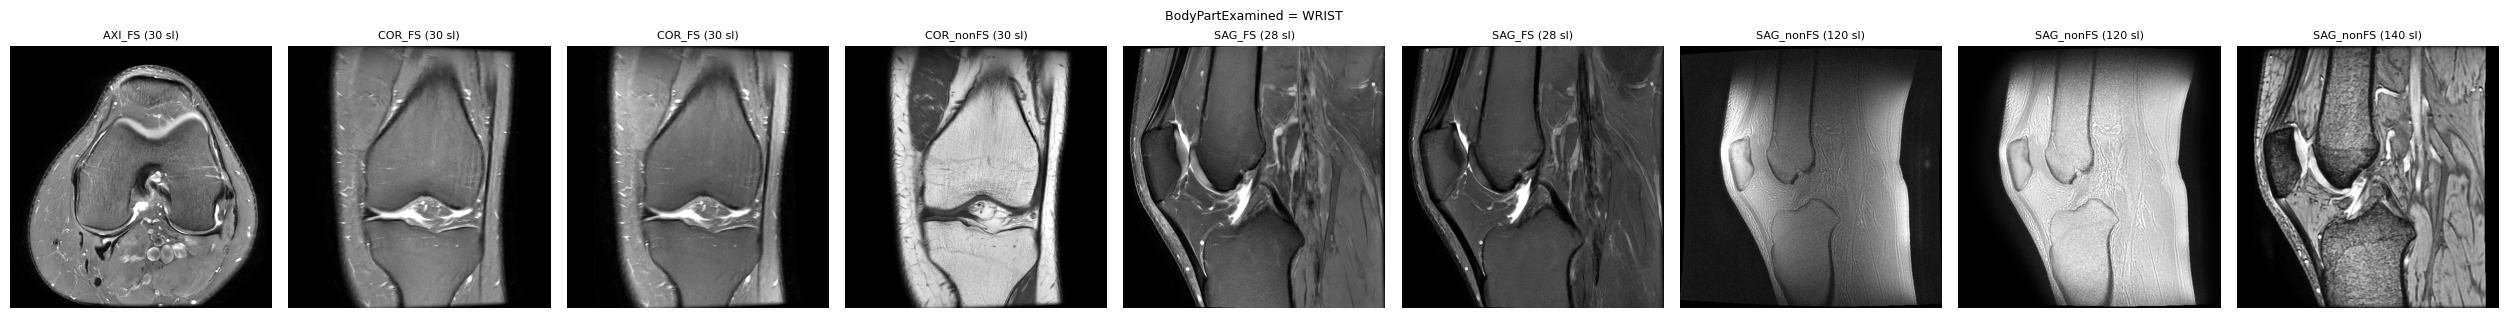

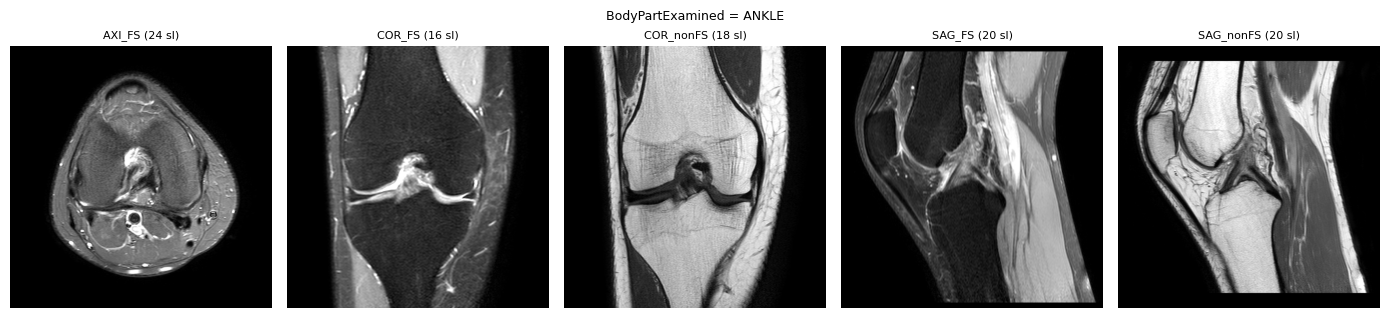

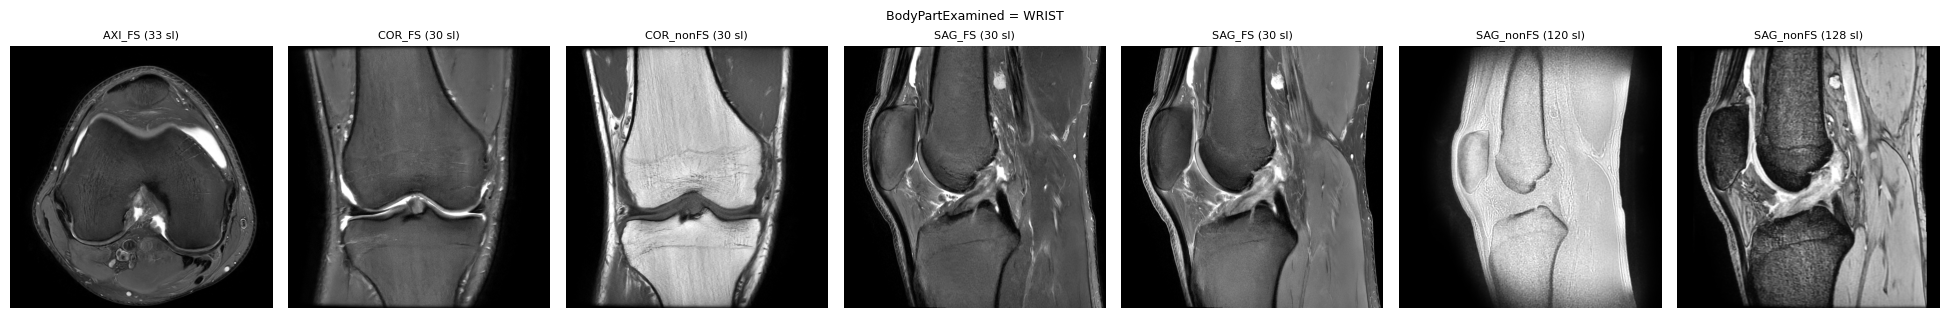

In [20]:
def show_study(st, title=""):
    s = series[series.StudyInstanceUID == st].sort_values("kind")
    fig, axes = plt.subplots(1, len(s), figsize=(2.8 * len(s), 3.2))
    for ax, r in zip(np.atleast_1d(axes), s.itertuples()):
        ax.imshow(load_mid(st, r.SeriesInstanceUID), cmap="gray"); ax.axis("off")
        ax.set_title(f"{r.kind} ({r.n_slices} sl)", fontsize=8)
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.show()

# (a) one gold study, every series
g1 = train[train.is_gold].sample(1, random_state=SEED).iloc[0]
show_study(g1.StudyInstanceUID, "GOLD positives: " + ", ".join(l for l in LABELS if g1[l] == 1))

# (b) effusion yes vs no, sagittal FS middle slice
sag = series[series.kind == "SAG_FS"].drop_duplicates("StudyInstanceUID").set_index("StudyInstanceUID").SeriesInstanceUID
gs = train[train.is_gold & train.StudyInstanceUID.isin(sag.index)]
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for i, (name, d) in enumerate([("Effusion = 1", gs[gs.Effusion == 1]), ("Effusion = 0", gs[gs.Effusion == 0])]):
    for j, st in enumerate(d.sample(min(5, len(d)), random_state=SEED).StudyInstanceUID):
        axes[i, j].imshow(load_mid(st, sag[st]), cmap="gray"); axes[i, j].set_title(name, fontsize=9)
    for ax in axes[i]: ax.axis("off")
plt.tight_layout(); plt.show()

# (c) are the "ANKLE / WRIST / HEAD / BRAIN / LIVER" studies really knees?
odd = sh[sh.BodyPartExamined.isin(["ANKLE", "WRIST", "HEAD", "BRAIN", "LIVER"])]
for r in odd.sample(min(4, len(odd)), random_state=SEED).itertuples():
    show_study(r.StudyInstanceUID, f"BodyPartExamined = {r.BodyPartExamined}")

In [21]:
study_meta = train[["StudyInstanceUID", "is_gold", "lang", "n_chars"]].merge(
    sh[["StudyInstanceUID", "vendor", "scanner", "MagneticFieldStrength", "PatientSex", "Laterality", "BodyPartExamined"]],
    on="StudyInstanceUID")
study_meta.to_csv(OUT / "study_meta.csv", index=False)
series.to_csv(OUT / "series_meta.csv", index=False)
cov.reset_index().to_csv(OUT / "series_coverage.csv", index=False)
print(sorted(p.name for p in OUT.glob("*.csv")))

['series_coverage.csv', 'series_header_audit.csv', 'series_meta.csv', 'slice_counts.csv', 'study_headers.csv', 'study_meta.csv']
